In [1]:
# RAG : Retrieval Augmented Generation 
# GPT -1 Paper - pDF loader (one per page)
# RCTS - list of document objects - chunks
# text-embed model - 3072 dimensions per chunk
# chroma db --> as retriever (top-k chunks)
# gpt-4o to grounded answer

In [1]:
!pip install langchain langchain-community langchain-openai langchain-text-splitters chromadb pypdf scikit-learn

In [2]:
# document loading
from langchain_community.document_loaders import PyPDFLoader
PDF_PATH="/Volumes/Work/Oracle15/2018 (OpenAI) (Arxiv) [GPT-1] Improving Language Understanding by Generative Pre-Training.pdf"
# creating loader object and loading the document
loader = PyPDFLoader(PDF_PATH)
# creating a list of document objects from the loader
docs = loader.load() # returns the list of doc objects

print(f"Total pages loaded: {len(docs)}")
print(f"Page content with 500 chars : {docs[0].page_content[:500]}")


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total pages loaded: 12
Page content with 500 chars : Improving Language Understanding
by Generative Pre-Training
Alec Radford
OpenAI
alec@openai.com
Karthik Narasimhan
OpenAI
karthikn@openai.com
Tim Salimans
OpenAI
tim@openai.com
Ilya Sutskever
OpenAI
ilyasu@openai.com
Abstract
Natural language understanding comprises a wide range of diverse tasks such
as textual entailment, question answering, semantic similarity assessment, and
document classiﬁcation. Although large unlabeled text corpora are abundant,
labeled data for learning these speciﬁc tas


In [5]:
# inspecting pages
for i,doc in enumerate(docs):
    preview = doc.page_content[:65].replace("\n"," ") #replace line break by space
    print(f"{i} | {len(doc.page_content)} | {preview}")

0 | 3355 | Improving Language Understanding by Generative Pre-Training Alec 
1 | 4904 | In this paper, we explore a semi-supervised approach for language
2 | 3301 | pre-trained language or machine translation model as auxiliary fe
3 | 2894 | Figure 1: (left) Transformer architecture and training objectives
4 | 4171 | Table 1: A list of the different tasks and datasets used in our e
5 | 3349 | Table 2: Experimental results on natural language inference tasks
6 | 2275 | Table 4: Semantic similarity and classiﬁcation results, comparing
7 | 4267 | Table 5: Analysis of various model ablations on different tasks. 
8 | 3835 | [2] J. L. Ba, J. R. Kiros, and G. E. Hinton. Layer normalization.
9 | 3487 | [24] F. Jiao, S. Wang, C.-H. Lee, R. Greiner, and D. Schuurmans. 
10 | 3936 | [46] A. Rahman and V . Ng. Resolving complex cases of deﬁnite pro
11 | 721 | [68] D. Yu, L. Deng, and G. Dahl. Roles of pre-training and ﬁne-t


In [3]:
# chunking - text splitting
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 200,
    chunk_overlap = 40
)

chunks = text_splitter.split_documents(docs)
print(f"Pages Loaded: {len(docs)}")
print(f"Chunks created: {len(chunks)}")


Pages Loaded: 12
Chunks created: 265


In [4]:
# inspecting chunks

for i in range(4):
    print(f"Chunk{i}{'-'*50}")
    print(f"Metadata: {chunks[i].metadata}")
    print(f"Length: {len(chunks[i].page_content)}")
    print(f"Content: {chunks[i].page_content}")

Chunk0--------------------------------------------------
Metadata: {'producer': 'pdfTeX-1.40.18', 'creator': 'LaTeX with hyperref package', 'creationdate': '2018-06-08T19:14:34+00:00', 'author': '', 'keywords': '', 'moddate': '2018-06-08T19:14:34+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.18 (TeX Live 2017) kpathsea version 6.2.3', 'subject': '', 'title': '', 'trapped': '/False', 'source': '/Volumes/Work/Oracle15/2018 (OpenAI) (Arxiv) [GPT-1] Improving Language Understanding by Generative Pre-Training.pdf', 'total_pages': 12, 'page': 0, 'page_label': '1'}
Length: 198
Content: Improving Language Understanding
by Generative Pre-Training
Alec Radford
OpenAI
alec@openai.com
Karthik Narasimhan
OpenAI
karthikn@openai.com
Tim Salimans
OpenAI
tim@openai.com
Ilya Sutskever
OpenAI
Chunk1--------------------------------------------------
Metadata: {'producer': 'pdfTeX-1.40.18', 'creator': 'LaTeX with hyperref package', 'creationdate': '2018-06-08T19:14:34+00:00', 'aut

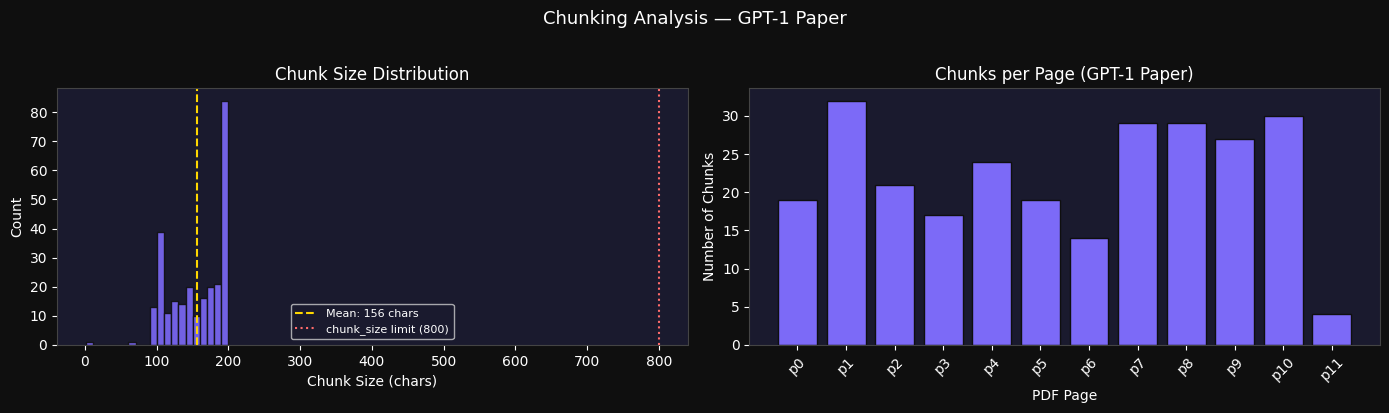

In [8]:
# Visualize chunk size distribution
import matplotlib.pyplot as plt # pip install matplotlib
import numpy as np

chunk_sizes = [len(c.page_content) for c in chunks]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.patch.set_facecolor('#0f0f0f')

for ax in axes:
    ax.set_facecolor('#1a1a2e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    ax.title.set_color('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#444')

# Histogram
axes[0].hist(chunk_sizes, bins=20, color='#7c6af7', edgecolor='#0f0f0f', alpha=0.9)
axes[0].axvline(np.mean(chunk_sizes), color='#ffd700', linestyle='--',
                linewidth=1.5, label=f'Mean: {np.mean(chunk_sizes):.0f} chars')
axes[0].axvline(800, color='#ff6b6b', linestyle=':', linewidth=1.5, label='chunk_size limit (800)')
axes[0].set_xlabel('Chunk Size (chars)')
axes[0].set_ylabel('Count')
axes[0].set_title('Chunk Size Distribution')
axes[0].legend(facecolor='#1a1a2e', labelcolor='white', fontsize=8)

# Chunks per page
from collections import Counter
page_counts = Counter(c.metadata.get('page', 0) for c in chunks)
pages = sorted(page_counts.keys())
counts = [page_counts[p] for p in pages]
axes[1].bar([f"p{p}" for p in pages], counts, color='#7c6af7', edgecolor='#0f0f0f')
axes[1].set_xlabel('PDF Page')
axes[1].set_ylabel('Number of Chunks')
axes[1].set_title('Chunks per Page (GPT-1 Paper)')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Chunking Analysis — GPT-1 Paper', color='white', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [6]:
# embeddings

from langchain_openai import OpenAIEmbeddings
embedding_model = OpenAIEmbeddings(model="text-embedding-3-large")

# embed single chunk - see what vector looks like
sample_text = chunks[0].page_content
sample_vector = embedding_model.embed_query(sample_text)

print(f"Sample text : {sample_text[:150]}")
print("-"*50)
print(f"Vector len : {len(sample_vector)} ")
print("-"*50)
print(f"First 10 dimensions : {[round(v,6) for v in sample_vector[:10]]}")

Sample text : Improving Language Understanding
by Generative Pre-Training
Alec Radford
OpenAI
alec@openai.com
Karthik Narasimhan
OpenAI
karthikn@openai.com
Tim Sali
--------------------------------------------------
Vector len : 3072 
--------------------------------------------------
First 10 dimensions : [0.02211, 0.017532, -0.018173, -0.029053, -0.009399, 0.034088, -0.010437, 0.033325, -0.0177, -0.016083]


In [7]:
# store vectors in chroma db
from langchain_chroma import Chroma
print(f"Embedding {len(chunks)} chunks and storing it in chroma db")

vectorstore = Chroma.from_documents(
    documents = chunks,
    embedding = embedding_model,
    persist_directory = "./hcl_test_db",
    collection_name = "gpt1_paper"
)

total = vectorstore._collection.count()
print(f"Chunks stored: {total}")

Embedding 265 chunks and storing it in chroma db
Chunks stored: 265


In [8]:
# peak inside the chroma db
collection_data = vectorstore._collection.get(
    include=["embeddings", "documents", "metadatas"]
)

ids = collection_data['ids']
embeddings = collection_data['embeddings']
documents = collection_data['documents']
metadatas = collection_data['metadatas']

for i in range(5):
    print(f"Chunk{i} | ID : {ids[i]}")
    print(f"Metadata  | ID : {metadatas[i]}")
    print(f"Content | ID : {documents[i][:100]}")
    print(f"Vector : {[round(v,6) for v in embeddings[i][:5]]}")
    print()

Chunk0 | ID : 7af56a11-1e76-40d5-bbfb-6499a5ff4b26
Metadata  | ID : {'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.18 (TeX Live 2017) kpathsea version 6.2.3', 'trapped': '/False', 'author': '', 'total_pages': 12, 'moddate': '2018-06-08T19:14:34+00:00', 'producer': 'pdfTeX-1.40.18', 'creator': 'LaTeX with hyperref package', 'subject': '', 'source': '/Volumes/Work/Oracle15/2018 (OpenAI) (Arxiv) [GPT-1] Improving Language Understanding by Generative Pre-Training.pdf', 'page_label': '1', 'keywords': '', 'creationdate': '2018-06-08T19:14:34+00:00', 'page': 0, 'title': ''}
Content | ID : Improving Language Understanding
by Generative Pre-Training
Alec Radford
OpenAI
alec@openai.com
Kart
Vector : [np.float64(0.022079), np.float64(0.017532), np.float64(-0.018173), np.float64(-0.029068), np.float64(-0.009422)]

Chunk1 | ID : eb6fe735-d3ff-4936-b06e-e17f23ccbdcb
Metadata  | ID : {'keywords': '', 'title': '', 'page_label': '1', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159

In [9]:
# dummy retrieval function with cosine similarity 

def retrieve_with_scores(query:str, k:int=3):
    '''retrieve the top-k chunks with cosine scores'''
    results = vectorstore.similarity_search_with_relevance_scores(query, k=k)
    print(f"Query: {query}")
    print(f"Top {k} results :\n")
    for i, (doc,score) in enumerate(results):
        print(f"Rank {i+1} | Score: {score:.4f} | Page: {doc.metadata.get('page', '?')}")
        print(f"{doc.page_content[:200]}.....")
        print()
    return results
    
results = retrieve_with_scores("Which datasets were used for Natural Language Inference ? ")

Query: Which datasets were used for Natural Language Inference ? 
Top 3 results :

Rank 1 | Score: 0.4839 | Page: 4
provides an overview of all the tasks and datasets.
Natural Language Inference The task of natural language inference (NLI), also known as recog-.....

Rank 2 | Score: 0.4621 | Page: 8
challenge. In TAC, 2009.
[5] S. R. Bowman, G. Angeli, C. Potts, and C. D. Manning. A large annotated corpus for learning natural
language inference. EMNLP, 2015......

Rank 3 | Score: 0.4618 | Page: 4
Table 1: A list of the different tasks and datasets used in our experiments.
Task Datasets
Natural language inference SNLI [5], MultiNLI [66], Question NLI [64], RTE [4], SciTail [25].....



In [10]:
# RAG 

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

llm       = ChatOpenAI(model="gpt-4o", temperature=0)
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

def rag_answer(query: str, show_sources: bool = True) -> str:
    """Full RAG pipeline — retrieve chunks from GPT-1 paper → generate answer with GPT-4o."""

    # Step 1 — retrieve relevant chunks from ChromaDB
    retrieved = retriever.invoke(query)

    # Step 2 — build context string with page references
    context = "\n\n".join(
        f"[Page {doc.metadata.get('page', '?')}]\n{doc.page_content}"
        for doc in retrieved
    )

    # Step 3 — construct prompt
    messages = [
        SystemMessage(content=(
            "You are a precise research paper assistant. "
            "Answer the question using ONLY the provided context from the GPT-1 paper. "
            "If the answer is not in the context, say: 'This is not covered in the retrieved sections.' "
            "Be specific, cite page numbers where possible, and do not hallucinate."
        )),
        HumanMessage(content=f"Context from GPT-1 paper:\n{context}\n\nQuestion: {query}")
    ]

    # Step 4 — call GPT-4o
    response = llm.invoke(messages)

    if show_sources:
        print("── Sources retrieved ──────────────────────────────────")
        for i, doc in enumerate(retrieved):
            print(f"  [{i+1}] Page {doc.metadata.get('page','?')} — {doc.page_content[:90]}...")
        print("───────────────────────────────────────────────────────")
        print()

    return response.content

In [12]:
# test the RAG pipeline

q1 = "What two-stage training procedure does GPT-1 use ? "

print(f"Q : {q1}\n")
print(rag_answer(q1))

Q : What two-stage training procedure does GPT-1 use ? 

── Sources retrieved ──────────────────────────────────
  [1] Page 2 — 3 Framework
Our training procedure consists of two stages. The ﬁrst stage is learning a hi...
  [2] Page 2 — model on a large corpus of text. This is followed by a ﬁne-tuning stage, where we adapt th...
  [3] Page 1 — corpus. We employ a two-stage training procedure. First, we use a language modeling object...
  [4] Page 7 — task-agnostic model through generative pre-training and discriminative ﬁne-tuning. By pre-...
  [5] Page 3 — Figure 1: (left) Transformer architecture and training objectives used in this work. (righ...
───────────────────────────────────────────────────────

GPT-1 uses a two-stage training procedure consisting of: 

1. **Unsupervised Pre-training**: This involves learning a high-capacity language model on a large corpus of text using a language modeling objective on the unlabeled data to learn the initial parameters of a neural network mo

In [13]:
# test the RAG pipeline

q2 = "How does GPT-1 handle different tasks during fine tuning ? "

print(f"Q : {q2}\n")
print(rag_answer(q2))

Q : How does GPT-1 handle different tasks during fine tuning ? 

── Sources retrieved ──────────────────────────────────
  [1] Page 7 — task-agnostic model through generative pre-training and discriminative ﬁne-tuning. By pre-...
  [2] Page 3 — Figure 1: (left) Transformer architecture and training objectives used in this work. (righ...
  [3] Page 3 — 3.3 Task-speciﬁc input transformations
For some tasks, like text classiﬁcation, we can dir...
  [4] Page 0 — gains on these tasks can be realized by generative pre-training of a language model
on a d...
  [5] Page 6 — different tasks as a function of LM pre-training updates. Performance per task is normaliz...
───────────────────────────────────────────────────────

GPT-1 handles different tasks during fine-tuning by converting all structured inputs into token sequences. This allows the model to be fine-tuned on various tasks, such as text classification, by adapting the input format to be compatible with the model's architecture. This pr